In [6]:
from google.colab import files
uploaded = files.upload()

Saving customer_booking.csv to customer_booking.csv


In [7]:
import pandas as pd
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()

(50000, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [8]:
df.info()
print(df["booking_complete"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [9]:
df.describe()


,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,1.000000,1.000000,1.000000,9.500000,1.000000


In [ ]:
for col in ["sales_channel", "trip_type", "flight_day", "route", "booking_origin"]:
    print(col, "->", df[col].nunique(), "different values")

print("Duplicate rows:", df.duplicated().sum())

sales_channel -> 2 different values
trip_type -> 3 different values
flight_day -> 7 different values
route -> 799 different values
booking_origin -> 104 different values
Duplicate rows: 719


In [10]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(49281, 14)


In [11]:
# 1. Days of the week to numbers
df["flight_day"] = df["flight_day"].map({"Mon":1,"Tue":2,"Wed":3,"Thu":4,"Fri":5,"Sat":6,"Sun":7})

# 2. Two new features
df["total_extras"] = df["wants_extra_baggage"] + df["wants_preferred_seat"] + df["wants_in_flight_meals"]
df["weekend_flight"] = (df["flight_day"] >= 6).astype(int)

# 3. Number codes for route and booking_origin
df["route"] = pd.factorize(df["route"])[0]
df["booking_origin"] = pd.factorize(df["booking_origin"])[0]

# 4. Yes/no columns for sales_channel and trip_type
df = pd.get_dummies(df, columns=["sales_channel", "trip_type"], drop_first=True, dtype=int)

print(df.shape)
print(df.dtypes)

(49281, 17)
num_passengers             int64
purchase_lead              int64
length_of_stay             int64
flight_hour                int64
flight_day                 int64
route                      int64
booking_origin             int64
wants_extra_baggage        int64
wants_preferred_seat       int64
wants_in_flight_meals      int64
flight_duration          float64
booking_complete           int64
total_extras               int64
weekend_flight             int64
sales_channel_Mobile       int64
trip_type_OneWay           int64
trip_type_RoundTrip        int64
dtype: object


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# X = the clues, y = what we want to predict
X = df.drop("booking_complete", axis=1)
y = df["booking_complete"]

# 80% to learn from, 20% held back for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build and train the forest of 200 trees
model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

print("Training customers:", len(X_train))
print("Test customers:", len(X_test))
print("Model trained")

Training customers: 39424
Test customers: 9857
Model trained


In [13]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred))

Accuracy: 0.849
AUC: 0.755
              precision    recall  f1-score   support

           0       0.86      0.98      0.92      8379
           1       0.48      0.10      0.17      1478

    accuracy                           0.85      9857
   macro avg       0.67      0.54      0.54      9857
weighted avg       0.80      0.85      0.80      9857



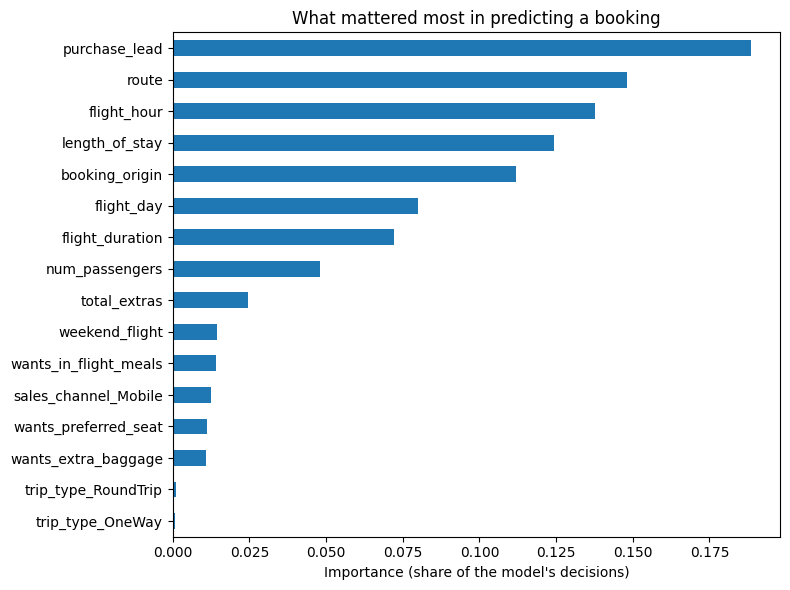

purchase_lead            0.189
route                    0.148
flight_hour              0.138
length_of_stay           0.124
booking_origin           0.112
flight_day               0.080
flight_duration          0.072
num_passengers           0.048
total_extras             0.024
weekend_flight           0.015
wants_in_flight_meals    0.014
sales_channel_Mobile     0.013
wants_preferred_seat     0.011
wants_extra_baggage      0.011
trip_type_RoundTrip      0.001
trip_type_OneWay         0.001
dtype: float64


In [14]:
import matplotlib.pyplot as plt

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()

importances.plot(kind="barh", figsize=(8, 6))
plt.title("What mattered most in predicting a booking")
plt.xlabel("Importance (share of the model's decisions)")
plt.tight_layout()
plt.savefig("importance.png", dpi=200)
plt.show()

print(importances.sort_values(ascending=False).round(3))

In [ ]:
from google.colab import files
files.download("importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred))

Accuracy: 0.849
AUC: 0.755
              precision    recall  f1-score   support

           0       0.86      0.98      0.92      8379
           1       0.48      0.10      0.17      1478

    accuracy                           0.85      9857
   macro avg       0.67      0.54      0.54      9857
weighted avg       0.80      0.85      0.80      9857



In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = cross_validate(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    X, y, cv=cv, scoring=["accuracy", "roc_auc", "recall", "precision"]
)
for name in ["accuracy", "roc_auc", "recall", "precision"]:
    scores = results["test_" + name]
    print(name, scores.round(3), "average:", scores.mean().round(3))

accuracy [0.849 0.849 0.848 0.849 0.849] average: 0.849
roc_auc [0.766 0.759 0.763 0.762 0.764] average: 0.763
recall [0.101 0.095 0.114 0.095 0.083] average: 0.098
precision [0.482 0.478 0.468 0.479 0.477] average: 0.477
